# Hands-on SCG Noise Reduction

This notebook reuses the SCG simulation and DSP functions from `dsp_tutorial.ipynb` to handle five common problems:

1. Band-limited high-frequency noise
2. Low-frequency baseline drift
3. Spike noise
4. Signal loss
5. Movement artifacts


## Setup and shared utilities

Install `requirements.txt` in the SensorAI project environment before running this notebook. `scg_simulate` appends six metadata values, so only the first `duration * fs` samples are retained.

In [1]:
from pathlib import Path
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pywt
from scipy.ndimage import median_filter
from scipy.signal import resample

repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'lib' / 'dsp.py').exists())
sys.path.insert(0, str(repo_root))

from lib.dsp import (
    add_band_limited_white_noise,
    butter_highpass_filter, butter_lowpass_filter, eemd_decomposition,
    savgol_filter, vmd_decomposition,
    scg_simulate, simple_moving_average_filter,
)

FS, DURATION, SEED = 100, 10, 42
N = FS * DURATION
np.random.seed(SEED)
random.seed(SEED)

anchor = scg_simulate(
    num_rows=1, duration=DURATION, sampling_rate=FS, pulse_type='db',
    heart_rate=(70, 70), respiratory_rate=(15, 15),
    systolic=(120, 120), diastolic=(80, 80),
    add_respiratory=False, noise_amplitude=0, random_state=SEED,
)[:N]
anchor = anchor - anchor.mean()
t = np.arange(N) / FS

def compare(noisy, results, title, xlim=None):
    plt.figure(figsize=(11, 3.5))
    plt.plot(t, anchor, 'k--', lw=1.3, label='Anchor signal')
    plt.plot(t, noisy, color='0.75', lw=1, label='Noisy signal')
    for name, signal in results.items():
        plt.plot(t, np.asarray(signal), lw=1.2, label=name)
    if xlim:
        plt.xlim(*xlim)
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 338.88it/s]

hr: 70 rr: 15 sp: 120 dp: 80


## 0. Noise analysis

Before selecting a denoising method, inspect two independently generated 10-second SCG signals in the time and frequency domains. The first is a synthetic **anchor signal**. The second is generated separately, contaminated with band-limited noise from 30 to 45 Hz, and called the **noisy signal**. The anchor signal is **not** the ground truth of the noisy signal—in real measurements, an exactly clean version of the observed signal is normally unavailable.

### 0.1 Time-domain observation

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 1148.50it/s]

hr: 82 rr: 18 sp: 135 dp: 85


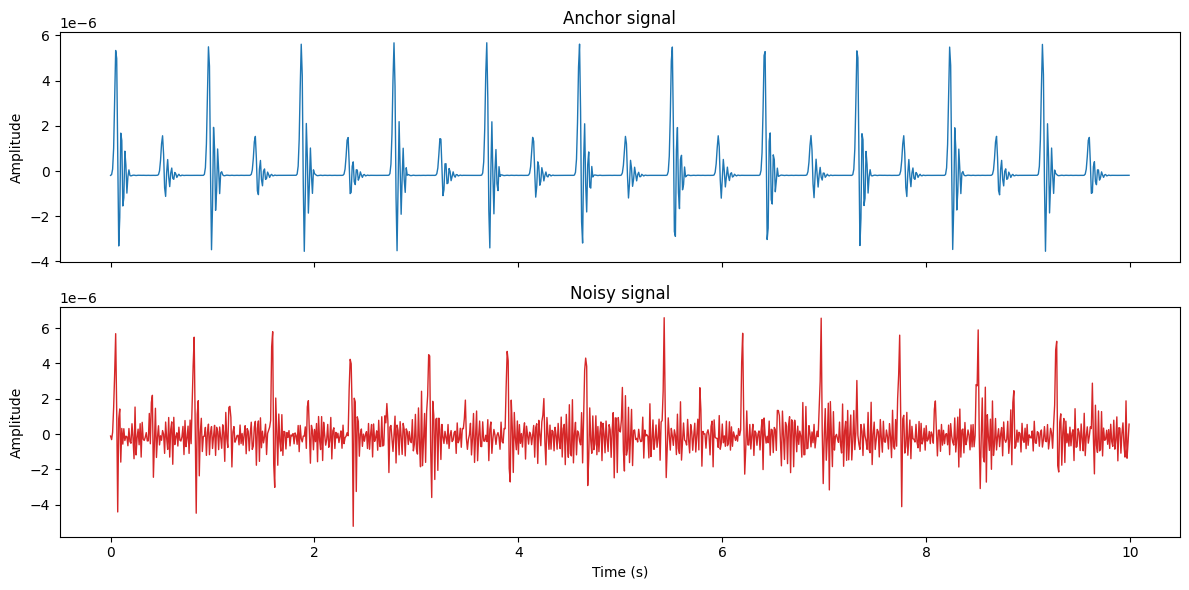

In [2]:
np.random.seed(100)
random.seed(100)
new_scg = scg_simulate(
    num_rows=1, duration=DURATION, sampling_rate=FS, pulse_type='db',
    heart_rate=(82, 82), respiratory_rate=(18, 18),
    systolic=(135, 135), diastolic=(85, 85),
    add_respiratory=False, noise_amplitude=0, random_state=100,
)[:N]
new_scg = new_scg - new_scg.mean()
noisy_signal = add_band_limited_white_noise(
    new_scg, noise_amplitude=1.5, sampling_rate=FS, lowcut=30, highcut=45
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, anchor, color='tab:blue', lw=1)
axes[0].set_title('Anchor signal')
axes[1].plot(t, noisy_signal, color='tab:red', lw=1)
axes[1].set_title('Noisy signal')
for ax in axes:
    ax.set_ylabel('Amplitude')
axes[1].set_xlabel('Time (s)')
plt.tight_layout(); plt.show()

### 0.2 Frequency-domain observation with the FFT

The FFT shows where signal energy is located in frequency, but it does not show when the noise occurs.

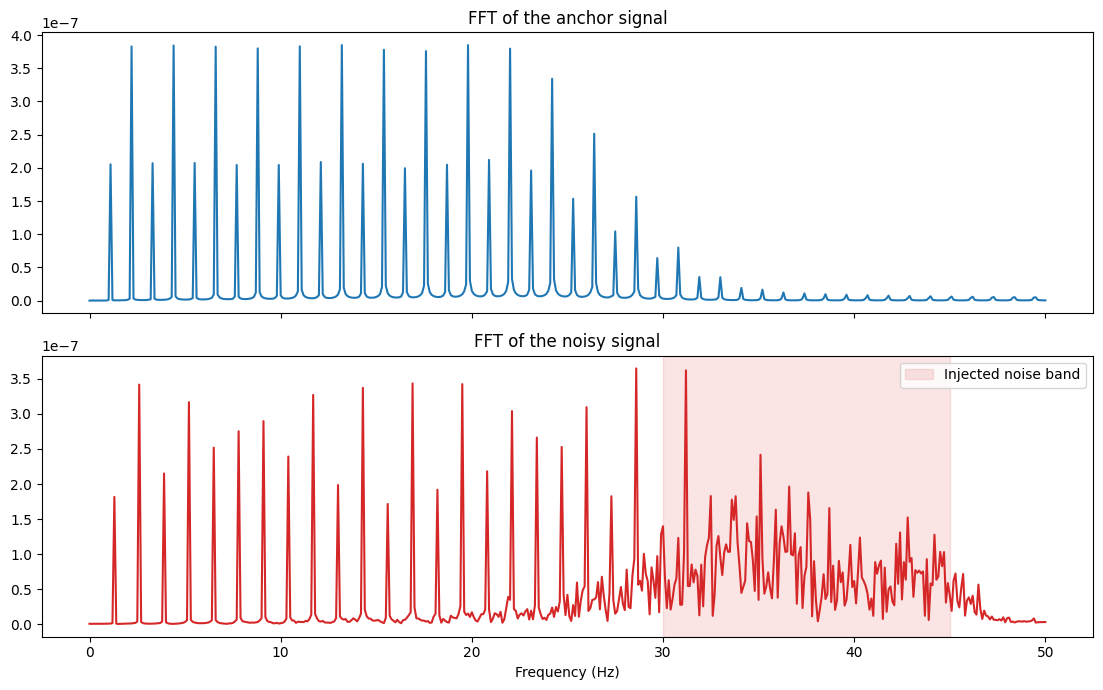

In [3]:
fft_frequency = np.fft.rfftfreq(N, d=1 / FS)
anchor_fft = 2 / N * np.abs(np.fft.rfft(anchor))
noisy_fft = 2 / N * np.abs(np.fft.rfft(noisy_signal))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(fft_frequency, anchor_fft, color='tab:blue')
axes[0].set_title('FFT of the anchor signal')
axes[1].plot(fft_frequency, noisy_fft, color='tab:red')
axes[1].axvspan(30, 45, color='tab:red', alpha=0.12, label='Injected noise band')
axes[1].set_title('FFT of the noisy signal')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].legend()
plt.tight_layout(); plt.show()

## 1. Low-frequency baseline drift

Compare two approaches:

- Estimate the slowly varying baseline with a long-window Savitzky–Golay filter, then subtract it from the original signal.
- Suppress low-frequency components directly with a Butterworth high-pass filter.

The simulated drift below is deliberately complex: it combines two slow oscillations, a nonlinear trend, and a smoothed random walk. The Savitzky–Golay window must be substantially longer than one heartbeat. A high-pass cutoff that is too high will attenuate genuine low-frequency physiology.

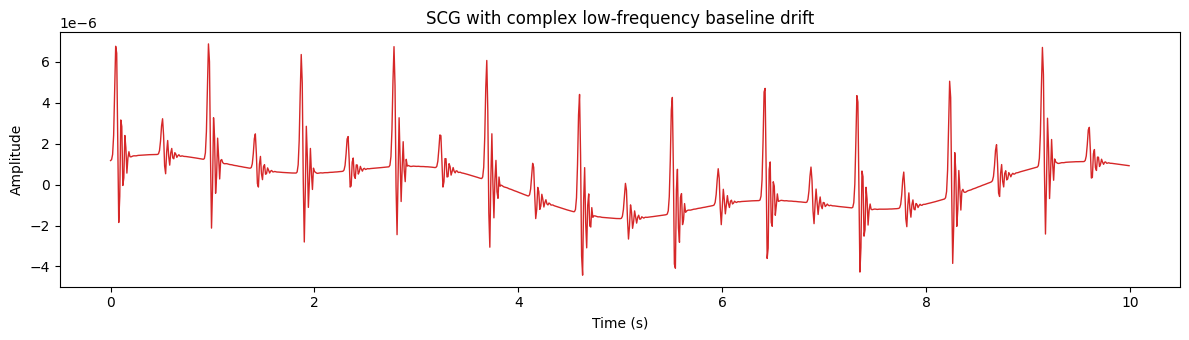

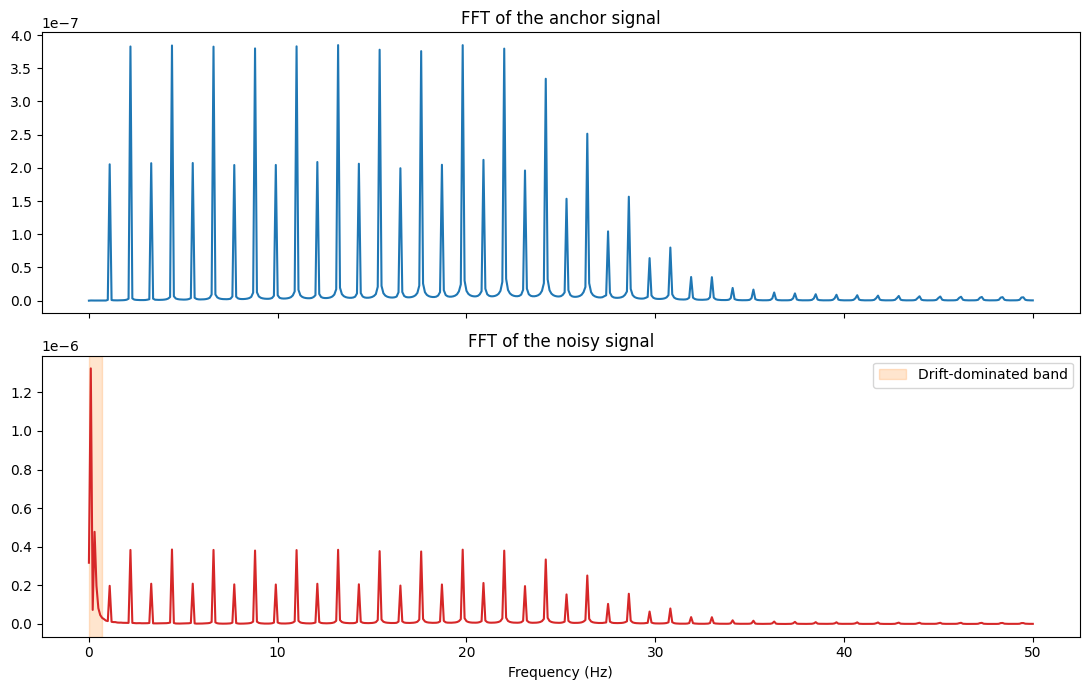

In [4]:
drift_rng = np.random.default_rng(2)
random_walk = np.cumsum(drift_rng.normal(size=N))
random_walk = savgol_filter(random_walk, window_length=301, polyorder=2)
random_walk = (random_walk - random_walk.mean()) / (random_walk.std() + 1e-12)
normalized_time = t / t[-1] - 0.5
drift = anchor.std() * (
    0.85 * np.sin(2 * np.pi * 0.12 * t + 0.4)
    + 0.55 * np.sin(2 * np.pi * 0.33 * t + 1.1)
    + 0.60 * (normalized_time ** 2 - np.mean(normalized_time ** 2))
    + 0.30 * random_walk
)
drift_noisy = anchor + drift

plt.figure(figsize=(12, 3.5))
plt.plot(t, drift_noisy, color='tab:red', lw=1)
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('SCG with complex low-frequency baseline drift')
plt.tight_layout(); plt.show()

drift_frequency = np.fft.rfftfreq(N, d=1 / FS)
anchor_drift_fft = 2 / N * np.abs(np.fft.rfft(anchor))
noisy_drift_fft = 2 / N * np.abs(np.fft.rfft(drift_noisy))
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(drift_frequency, anchor_drift_fft, color='tab:blue')
axes[0].set_title('FFT of the anchor signal')
axes[1].plot(drift_frequency, noisy_drift_fft, color='tab:red')
axes[1].axvspan(0, 0.7, color='tab:orange', alpha=.20, label='Drift-dominated band')
axes[1].set_title('FFT of the noisy signal')
axes[1].set_xlabel('Frequency (Hz)'); axes[1].legend()
plt.tight_layout(); plt.show()

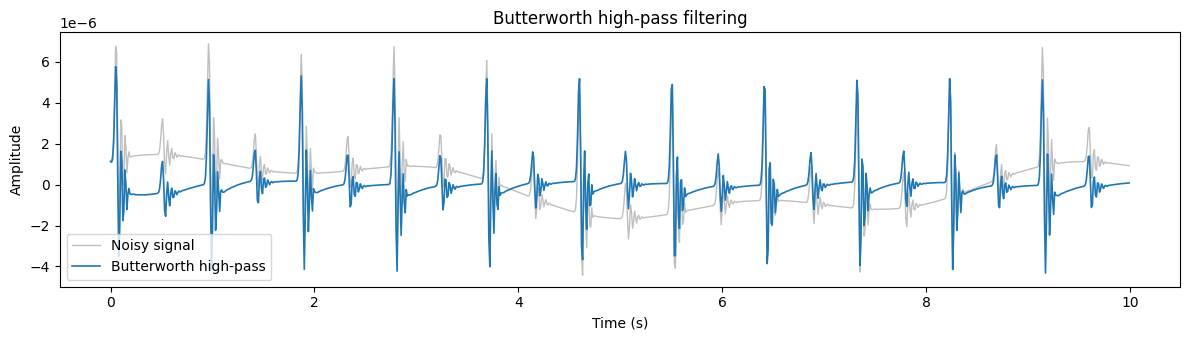

In [5]:
highpass_cleaned = butter_highpass_filter(drift_noisy, cutoff=0.6, fs=FS, order=3)

plt.figure(figsize=(12, 3.5))
plt.plot(t, drift_noisy, color='0.75', lw=1, label='Noisy signal')
plt.plot(t, highpass_cleaned, color='tab:blue', lw=1.2, label='Butterworth high-pass')
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('Butterworth high-pass filtering')
plt.legend(); plt.tight_layout(); plt.show()

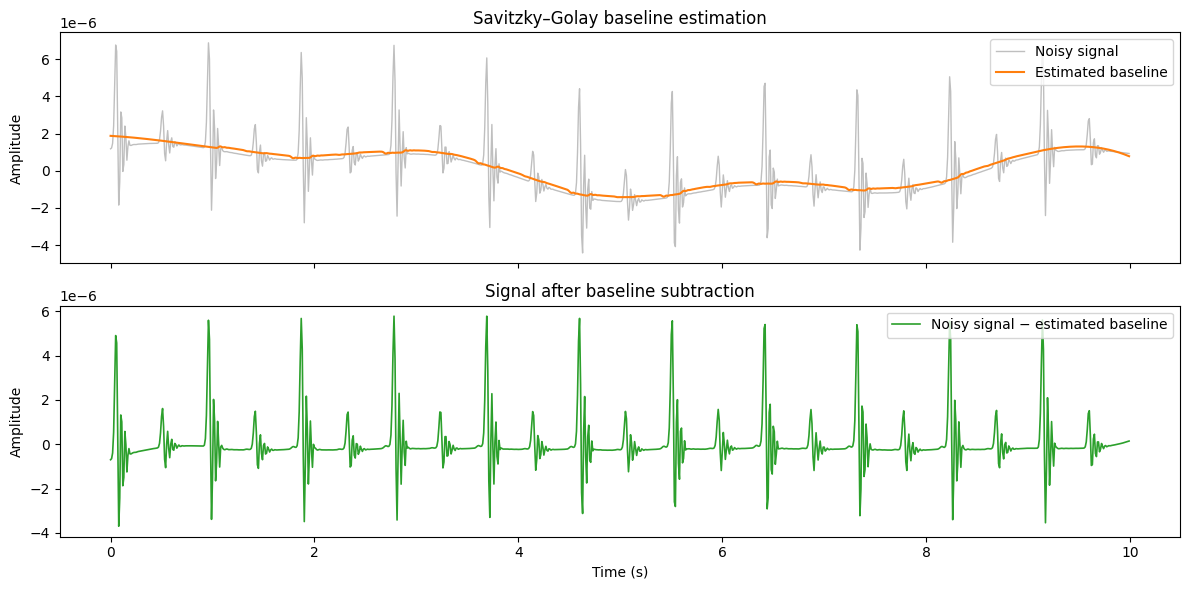

In [6]:
estimated_baseline = savgol_filter(drift_noisy, window_length=201, polyorder=3)
drift_cleaned = drift_noisy - estimated_baseline

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, drift_noisy, color='0.75', lw=1, label='Noisy signal')
axes[0].plot(t, estimated_baseline, color='tab:orange', lw=1.5, label='Estimated baseline')
axes[0].set_title('Savitzky–Golay baseline estimation')
axes[1].plot(t, drift_cleaned, color='tab:green', lw=1.2, label='Noisy signal − estimated baseline')
axes[1].set_title('Signal after baseline subtraction')
for ax in axes:
    ax.set_ylabel('Amplitude'); ax.legend(loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout(); plt.show()

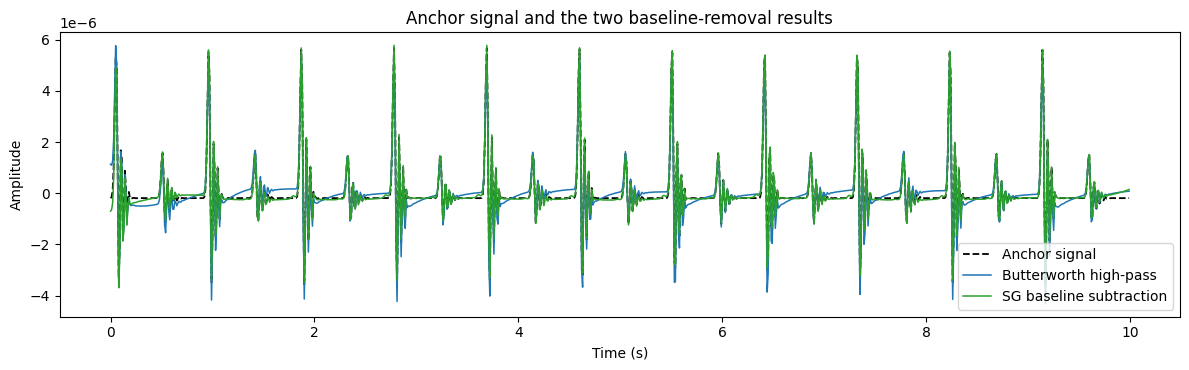

In [7]:
plt.figure(figsize=(12, 3.8))
plt.plot(t, anchor, 'k--', lw=1.3, label='Anchor signal')
plt.plot(t, highpass_cleaned, color='tab:blue', lw=1.1, label='Butterworth high-pass')
plt.plot(t, drift_cleaned, color='tab:green', lw=1.1, label='SG baseline subtraction')
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('Anchor signal and the two baseline-removal results')
plt.legend(); plt.tight_layout(); plt.show()

## 2. Band-limited high-frequency noise

Use `add_band_limited_white_noise` to add noise from 30 to 45 Hz, then compare two methods:

- When the noise is modest and clearly high-frequency, a short moving-average window can work well.
- A Butterworth low-pass filter provides an explicit cutoff frequency.

If the noise lies inside the useful SCG band, consider a band-stop or notch filter instead of blindly applying a low-pass filter.

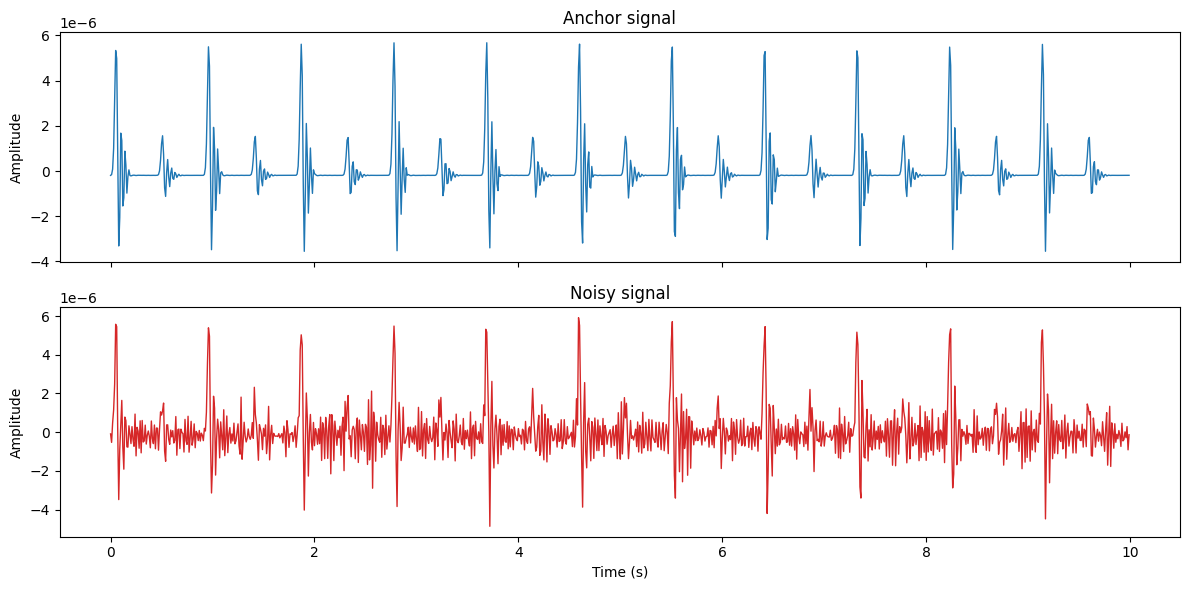

In [8]:
np.random.seed(1)
band_noisy = add_band_limited_white_noise(
    anchor, noise_amplitude=1.2, sampling_rate=FS, lowcut=30, highcut=45
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, anchor, color='tab:blue', lw=1)
axes[0].set_title('Anchor signal')
axes[1].plot(t, band_noisy, color='tab:red', lw=1)
axes[1].set_title('Noisy signal')
for ax in axes:
    ax.set_ylabel('Amplitude')
axes[1].set_xlabel('Time (s)')
plt.tight_layout(); plt.show()

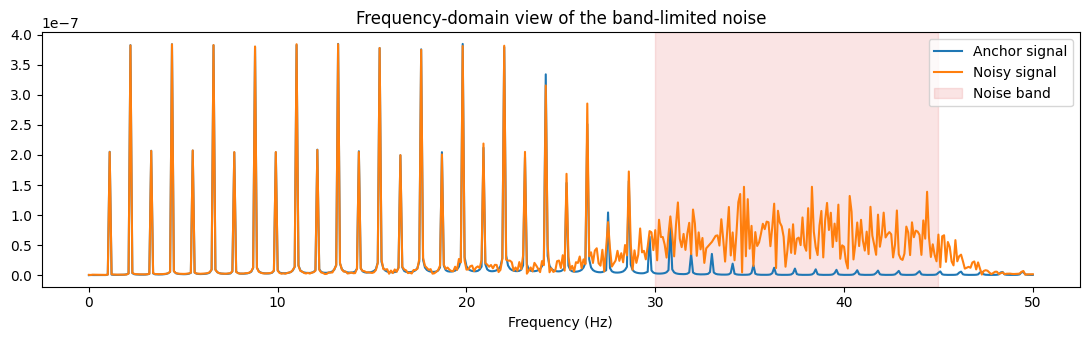

In [9]:
band_frequency = np.fft.rfftfreq(N, d=1 / FS)
band_anchor_fft = 2 / N * np.abs(np.fft.rfft(anchor))
band_noisy_fft = 2 / N * np.abs(np.fft.rfft(band_noisy))

plt.figure(figsize=(11, 3.5))
plt.plot(band_frequency, band_anchor_fft, label='Anchor signal')
plt.plot(band_frequency, band_noisy_fft, label='Noisy signal')
plt.axvspan(30, 45, color='tab:red', alpha=0.12, label='Noise band')
plt.xlabel('Frequency (Hz)')
plt.title('Frequency-domain view of the band-limited noise')
plt.legend(); plt.tight_layout(); plt.show()

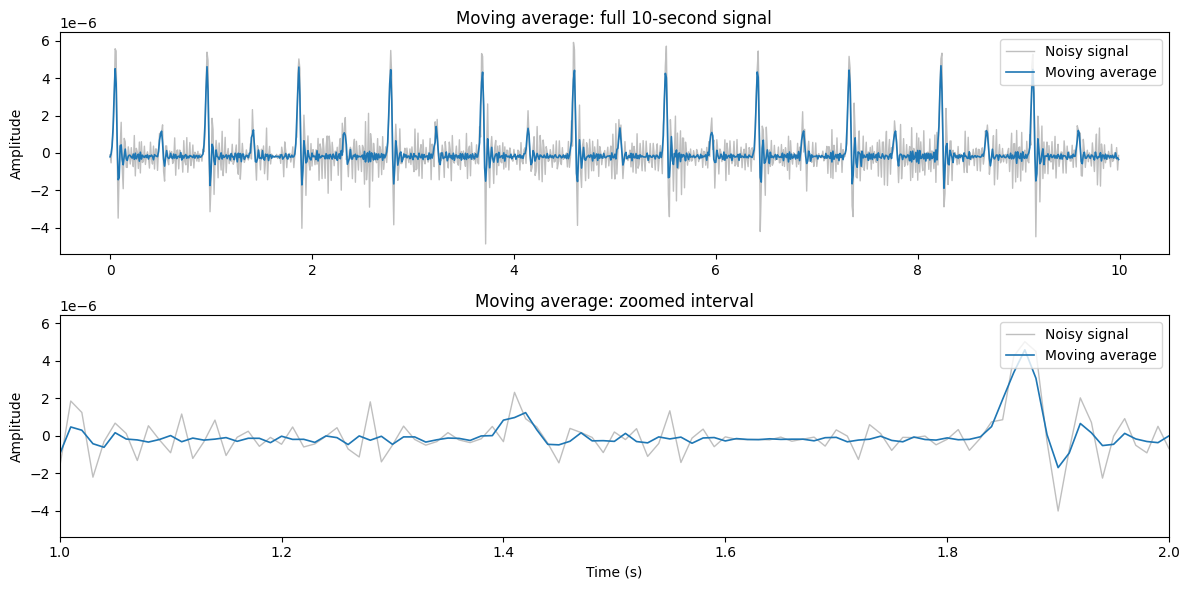

In [10]:
moving_average_band = simple_moving_average_filter(band_noisy, length=3)
zoom_start, zoom_end = 1.0, 2.0

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax in axes:
    ax.plot(t, band_noisy, color='0.75', lw=1, label='Noisy signal')
    ax.plot(t, moving_average_band, color='tab:blue', lw=1.2, label='Moving average')
    ax.set_ylabel('Amplitude')
    ax.legend(loc='upper right')
axes[0].set_title('Moving average: full 10-second signal')
axes[1].set_xlim(zoom_start, zoom_end)
axes[1].set_title('Moving average: zoomed interval')
axes[1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

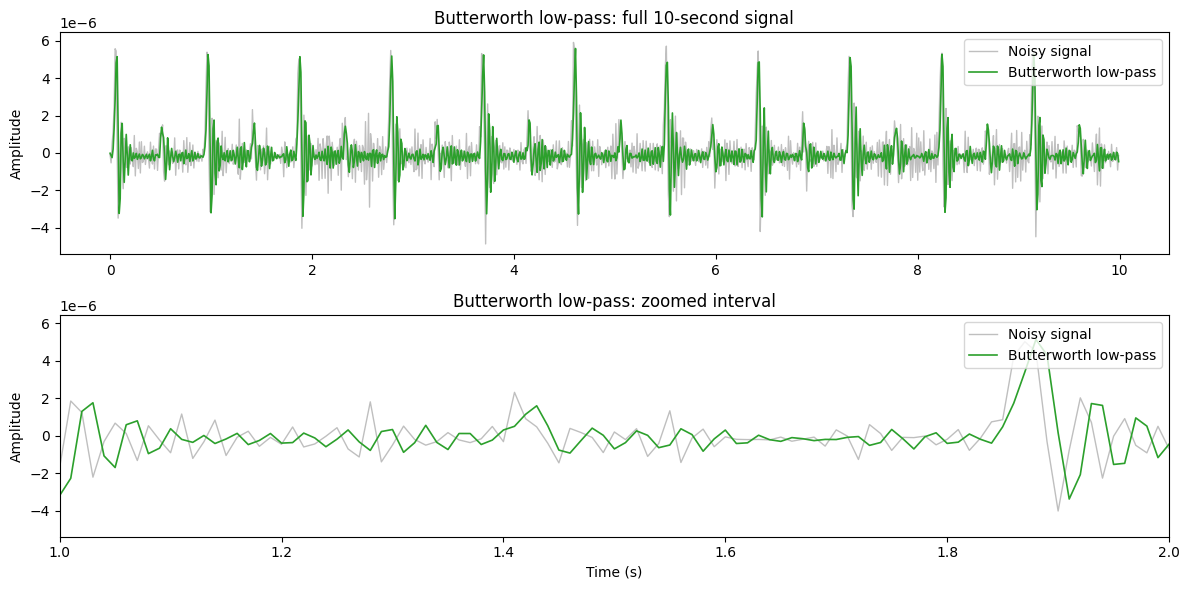

In [11]:
band_cleaned = butter_lowpass_filter(band_noisy, cutoff=30, fs=FS, order=4)
zoom_start, zoom_end = 1.0, 2.0

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax in axes:
    ax.plot(t, band_noisy, color='0.75', lw=1, label='Noisy signal')
    ax.plot(t, band_cleaned, color='tab:green', lw=1.2, label='Butterworth low-pass')
    ax.set_ylabel('Amplitude')
    ax.legend(loc='upper right')
axes[0].set_title('Butterworth low-pass: full 10-second signal')
axes[1].set_xlim(zoom_start, zoom_end)
axes[1].set_title('Butterworth low-pass: zoomed interval')
axes[1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

## 3. Spike noise → Median filter vs Moving average

This example injects exactly three isolated one-sample spikes over 10 seconds. Each corrupted sample is set to a very large positive value: 50 times the maximum absolute amplitude of the anchor signal. A median filter is insensitive to isolated extreme values. A moving average spreads each spike over neighboring samples, creates a wider bump, and attenuates genuine SCG peaks, so it is not a good choice for spike removal.

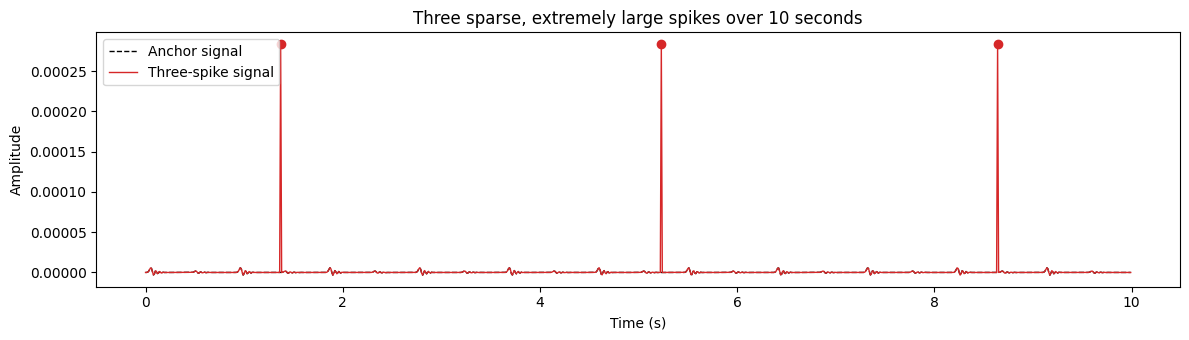

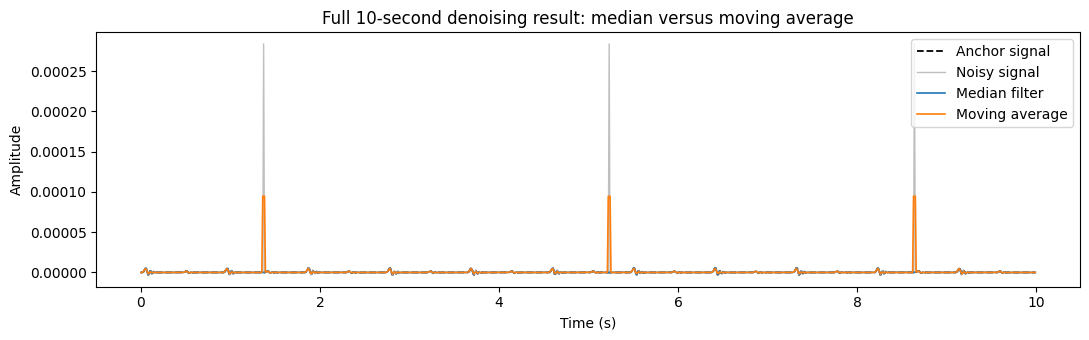

In [12]:
spike_positions = np.array([137, 523, 864])
spike_value = 50 * np.max(np.abs(anchor))
spike_noisy = anchor.copy()
spike_noisy[spike_positions] = spike_value
median_cleaned = median_filter(spike_noisy, size=3, mode='nearest')
moving_average = simple_moving_average_filter(spike_noisy, length=3)

plt.figure(figsize=(12, 3.5))
plt.plot(t, anchor, 'k--', lw=1, label='Anchor signal')
plt.plot(t, spike_noisy, color='tab:red', lw=1, label='Three-spike signal')
plt.scatter(t[spike_positions], spike_noisy[spike_positions], color='tab:red', zorder=3)
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('Three sparse, extremely large spikes over 10 seconds')
plt.legend(); plt.tight_layout(); plt.show()

compare(
    spike_noisy,
    {'Median filter': median_cleaned, 'Moving average': moving_average},
    'Full 10-second denoising result: median versus moving average',
)

## 4. Signal loss

Signal loss is not ordinary noise. Handle it according to the duration of the missing interval:

- **Case 1A — the missing timestamps are known:** directly fill a few missing samples with linear interpolation.
- **Case 1B — the missing positions are unknown:** if a downloaded 10-second record contains only a few fewer points than expected, resample the whole record to the expected length.
- **Case 2 — a moderate gap in the middle:** do not invent the missing SCG morphology. Drop the affected interval from downstream analysis.

Known missing regions are highlighted in the background. Case 1B cannot be highlighted because the exact missing positions are unknown.

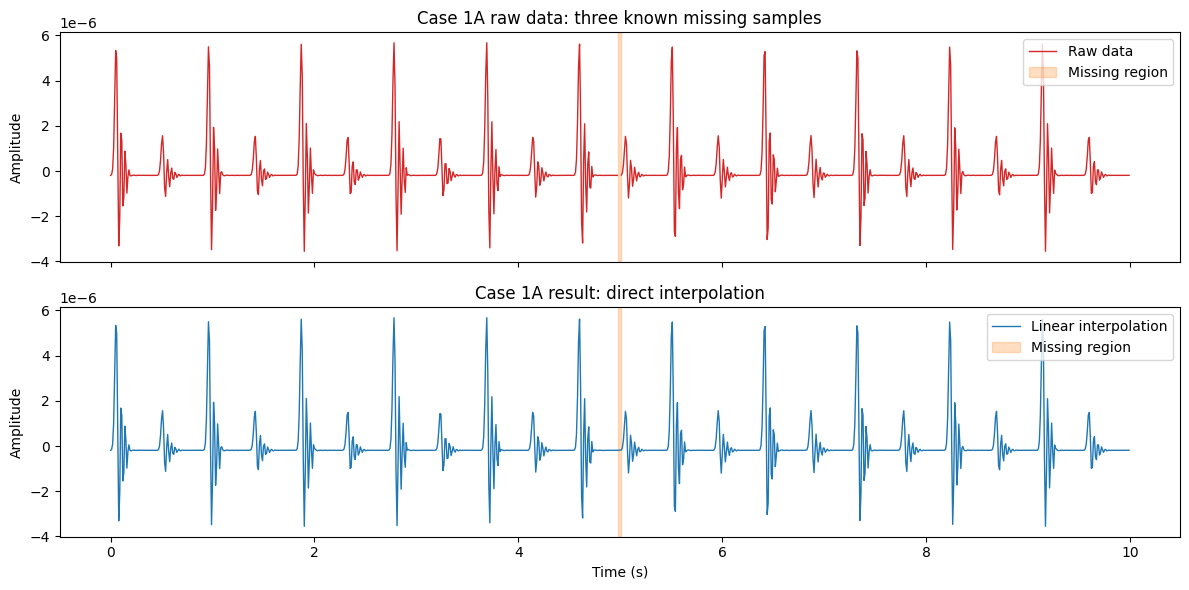

In [13]:
# Case 1A: three missing samples with known timestamps
short_missing = np.array([498, 499, 500])
short_raw = anchor.copy()
short_raw[short_missing] = np.nan
short_valid = np.isfinite(short_raw)
short_filled = short_raw.copy()
short_filled[short_missing] = np.interp(
    short_missing, np.flatnonzero(short_valid), short_raw[short_valid]
)
short_start, short_end = t[short_missing[0]], t[short_missing[-1]] + 1 / FS

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, short_raw, color='tab:red', lw=1, label='Raw data')
axes[0].set_title('Case 1A raw data: three known missing samples')
axes[1].plot(t, short_filled, color='tab:blue', lw=1, label='Linear interpolation')
axes[1].set_title('Case 1A result: direct interpolation')
for ax in axes:
    ax.axvspan(short_start, short_end, color='tab:orange', alpha=.25, label='Missing region')
    ax.set_ylabel('Amplitude'); ax.legend(loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout(); plt.show()

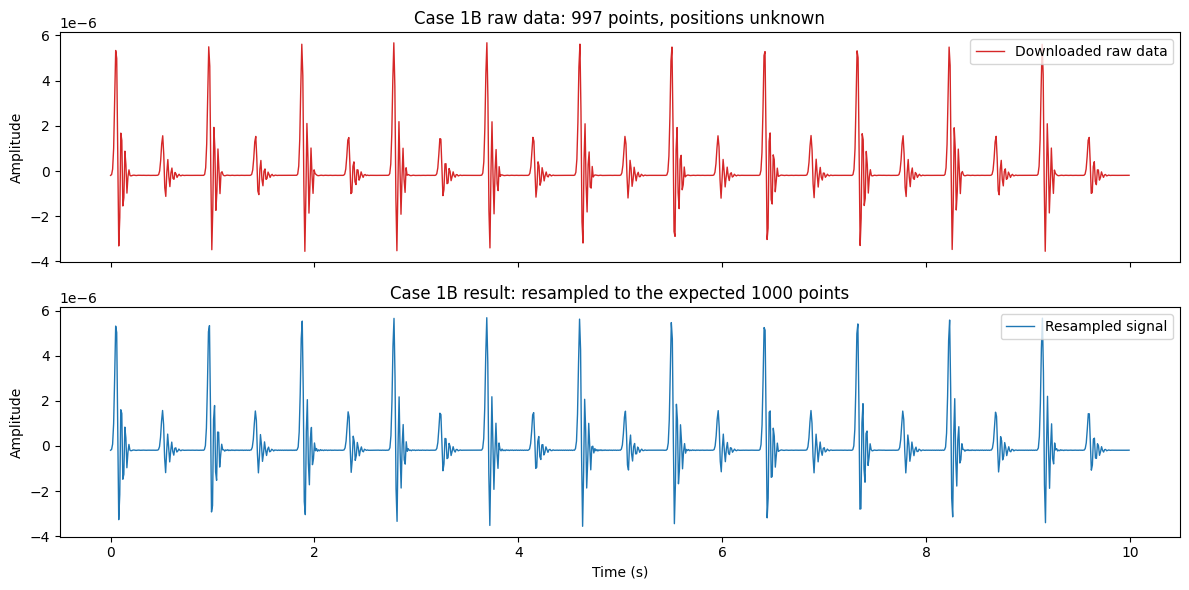

In [14]:
# Case 1B: the file contains three fewer points, but their positions are unknown
# The deleted indices are used only to simulate the download error; the repair does not use them.
downloaded_raw = np.delete(anchor, [250, 500, 750])
downloaded_time = np.linspace(0, DURATION, len(downloaded_raw), endpoint=False)
resampled_signal = resample(downloaded_raw, N)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(downloaded_time, downloaded_raw, color='tab:red', lw=1, label='Downloaded raw data')
axes[0].set_title(f'Case 1B raw data: {len(downloaded_raw)} points, positions unknown')
axes[1].plot(t, resampled_signal, color='tab:blue', lw=1, label='Resampled signal')
axes[1].set_title(f'Case 1B result: resampled to the expected {N} points')
for ax in axes:
    ax.set_ylabel('Amplitude'); ax.legend(loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout(); plt.show()

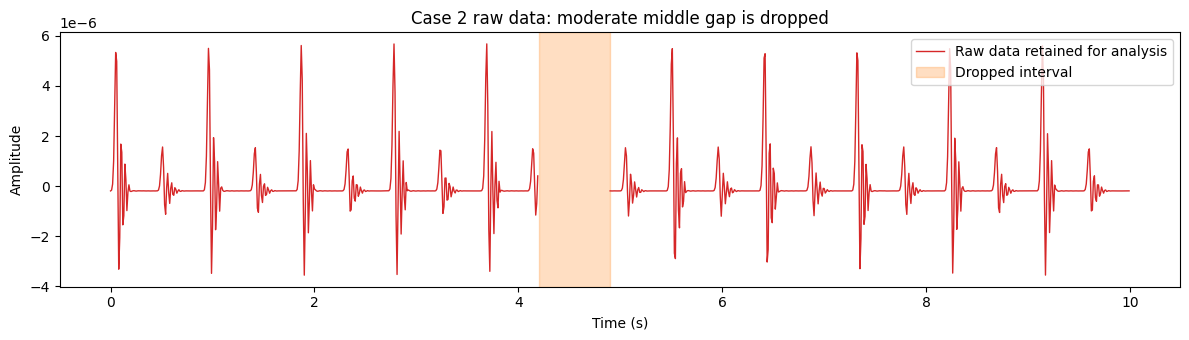

Case 2: drop 70 samples; keep 930 samples.


In [15]:
# Case 2: a moderate missing interval in the middle is dropped
moderate_gap = (t >= 4.20) & (t < 4.90)
moderate_raw = anchor.copy()
moderate_raw[moderate_gap] = np.nan
keep_for_analysis = ~moderate_gap

plt.figure(figsize=(12, 3.5))
plt.plot(t, moderate_raw, color='tab:red', lw=1, label='Raw data retained for analysis')
plt.axvspan(4.20, 4.90, color='tab:orange', alpha=.25, label='Dropped interval')
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('Case 2 raw data: moderate middle gap is dropped')
plt.legend(loc='upper right'); plt.tight_layout(); plt.show()
print(f'Case 2: drop {moderate_gap.sum()} samples; keep {keep_for_analysis.sum()} samples.')

## 5. Movement artifacts: decompose, select, and reconstruct

Movement artifacts are often nonstationary mixtures. The raw noisy SCG is shown first, followed by three decomposition approaches from `dsp_tutorial`: wavelet decomposition, ensemble empirical mode decomposition (EEMD), and variational mode decomposition (VMD). Each approach discards components dominated by very-low-frequency motion or very-high-frequency vibration, then reconstructs the retained components.

In real data, do not always discard the same component. Select components using evidence such as frequency band, energy, kurtosis, and correlation with a motion-reference channel.

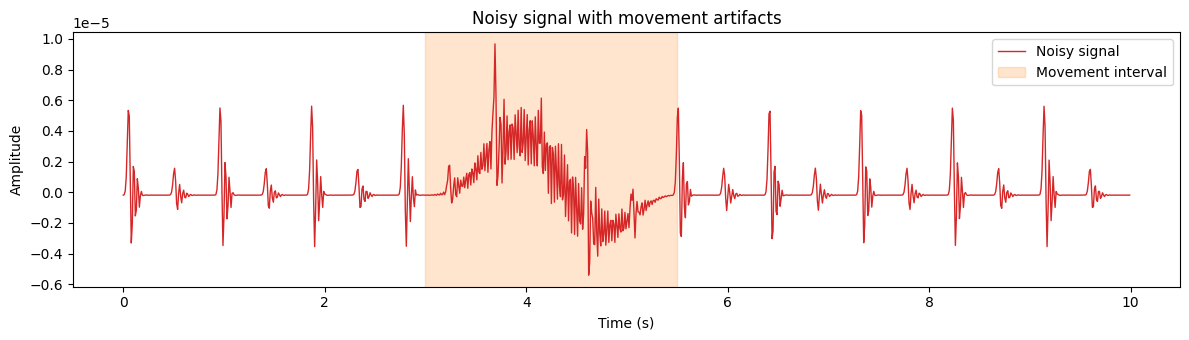

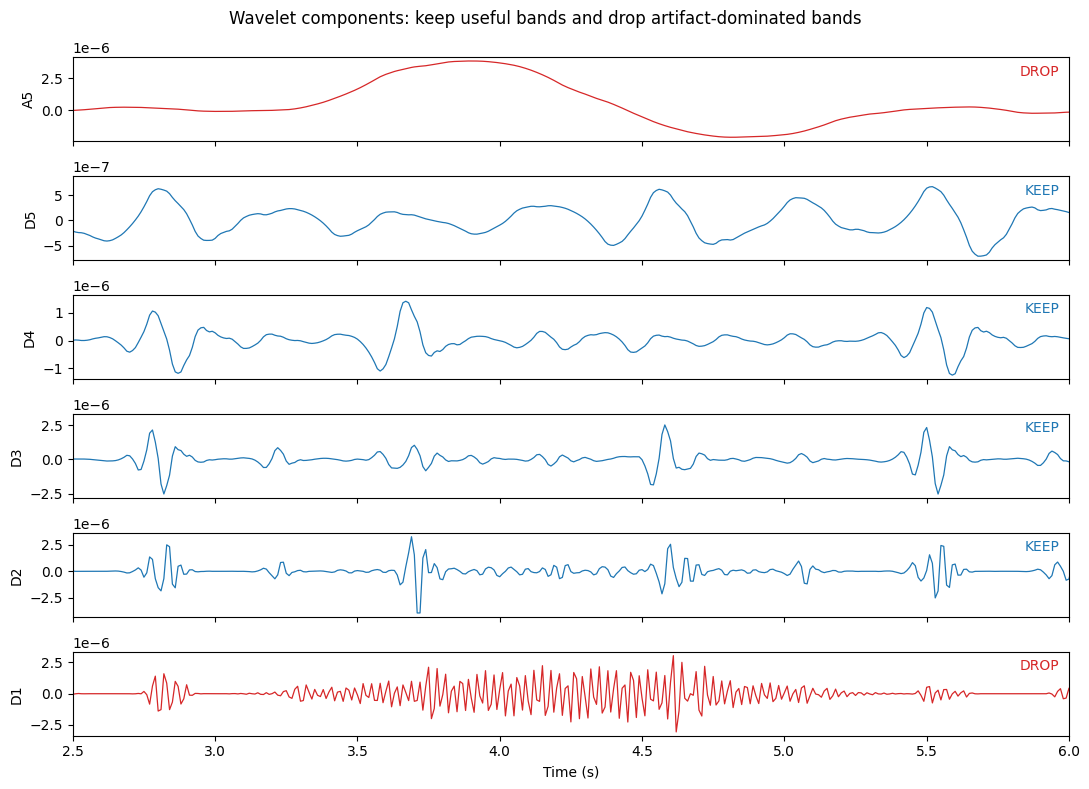

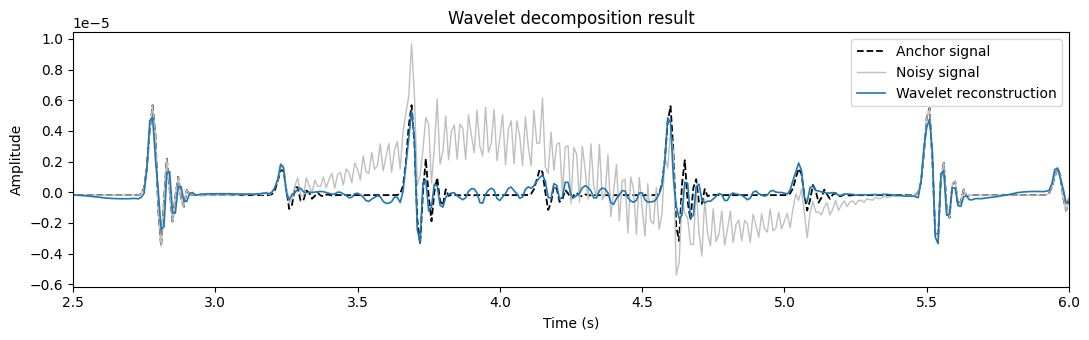

In [16]:
rng = np.random.default_rng(5)
motion_region = (t >= 3.0) & (t < 5.5)
u = t[motion_region] - t[motion_region][0]
envelope = np.hanning(motion_region.sum())
artifact = np.zeros_like(anchor)
artifact[motion_region] = anchor.std() * envelope * (
    5.0 * np.sin(2 * np.pi * 0.35 * u)
    + 2.0 * np.sin(2 * np.pi * 35 * u)
    + 0.2 * rng.standard_normal(motion_region.sum())
)
motion_noisy = anchor + artifact

plt.figure(figsize=(12, 3.5))
plt.plot(t, motion_noisy, color='tab:red', lw=1, label='Noisy signal')
plt.axvspan(3.0, 5.5, color='tab:orange', alpha=.20, label='Movement interval')
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('Noisy signal with movement artifacts')
plt.legend(loc='upper right'); plt.tight_layout(); plt.show()

# [A5, D5, D4, D3, D2, D1] are six components ordered from low to high frequency
coeffs = pywt.wavedec(motion_noisy, 'db4', level=5)
names = ['A5: <1.6 Hz', 'D5: 1.6–3.1 Hz', 'D4: 3.1–6.2 Hz',
         'D3: 6.2–12.5 Hz', 'D2: 12.5–25 Hz', 'D1: 25–50 Hz']
keep = [False, True, True, True, True, False]
components = []
for i in range(len(coeffs)):
    one_component = [np.zeros_like(c) for c in coeffs]
    one_component[i] = coeffs[i]
    components.append(pywt.waverec(one_component, 'db4')[:N])
motion_cleaned = np.sum([c for c, use in zip(components, keep) if use], axis=0)

fig, axes = plt.subplots(6, 1, figsize=(11, 8), sharex=True)
for ax, component, name, use in zip(axes, components, names, keep):
    ax.plot(t, component, lw=0.9, color='tab:blue' if use else 'tab:red')
    ax.set_ylabel(name.split(':')[0])
    ax.text(.99, .78, 'KEEP' if use else 'DROP', transform=ax.transAxes,
            ha='right', color='tab:blue' if use else 'tab:red')
axes[-1].set_xlabel('Time (s)')
axes[-1].set_xlim(2.5, 6.0)
fig.suptitle('Wavelet components: keep useful bands and drop artifact-dominated bands')
plt.tight_layout(); plt.show()

compare(motion_noisy, {'Wavelet reconstruction': motion_cleaned},
        'Wavelet decomposition result', xlim=(2.5, 6.0))

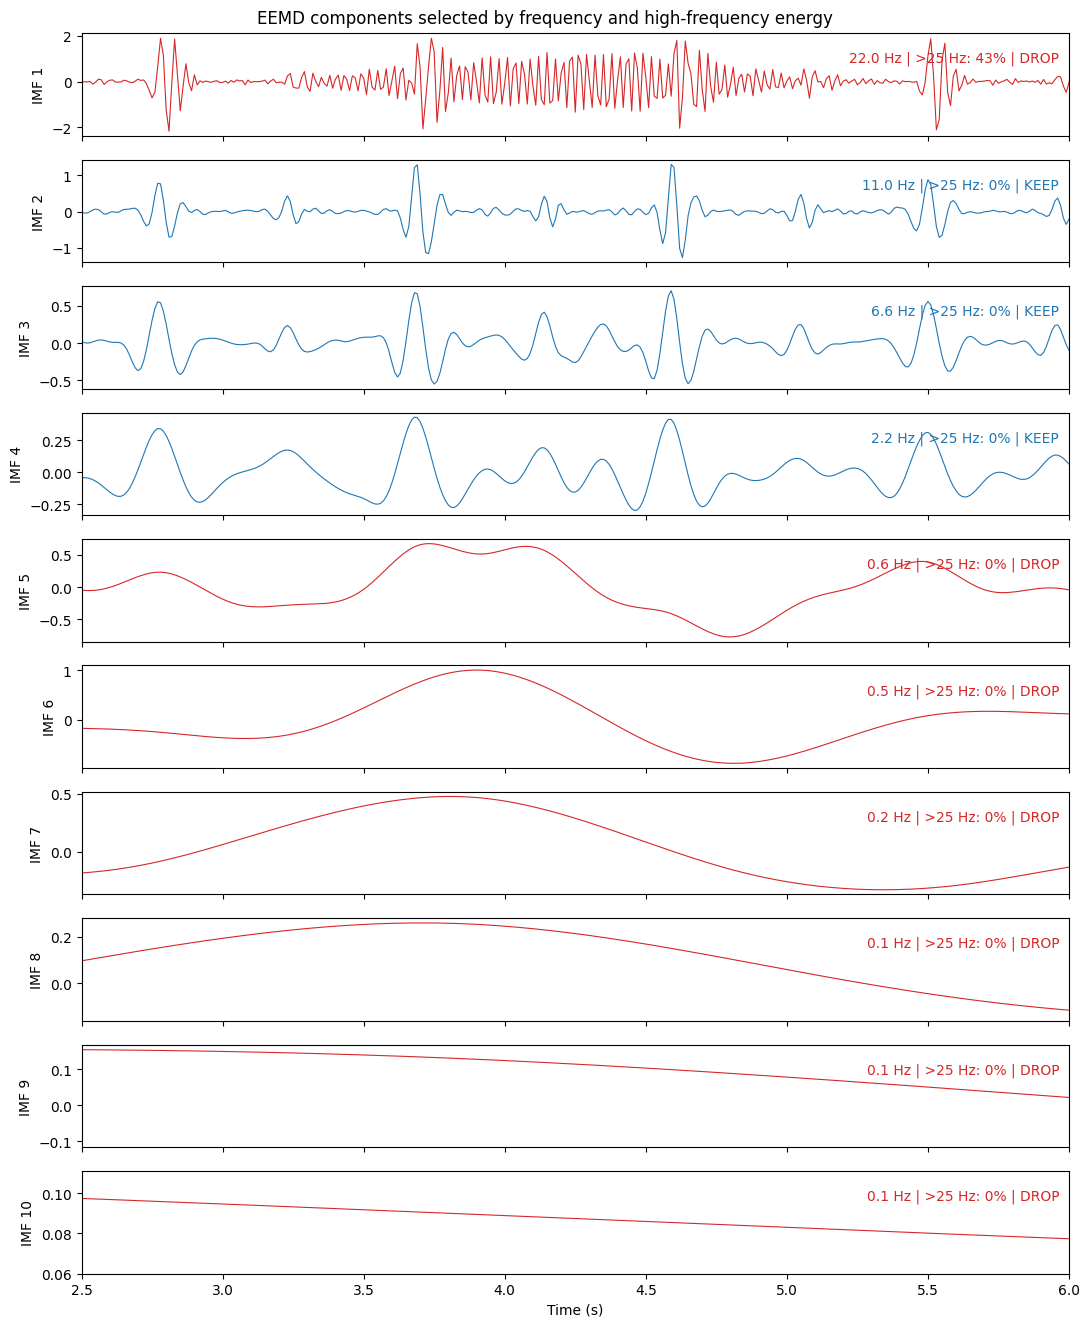

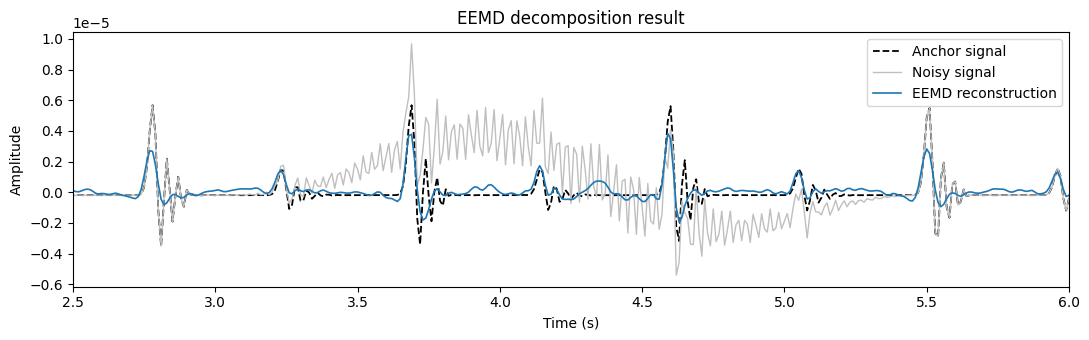

In [17]:
def dominant_frequency(component):
    frequency = np.fft.rfftfreq(len(component), d=1 / FS)
    magnitude = np.abs(np.fft.rfft(component))
    magnitude[0] = 0
    return frequency[np.argmax(magnitude)]

def high_frequency_energy_ratio(component, cutoff=25.0):
    frequency = np.fft.rfftfreq(len(component), d=1 / FS)
    power = np.abs(np.fft.rfft(component)) ** 2
    return power[frequency > cutoff].sum() / power.sum()

eemd_modes = eemd_decomposition(
    motion_noisy, noise_width=0.05, ensemble_size=50
)
eemd_peak_hz = np.array([dominant_frequency(mode) for mode in eemd_modes])
eemd_high_ratio = np.array([
    high_frequency_energy_ratio(mode) for mode in eemd_modes
])
eemd_keep = (
    (eemd_peak_hz >= 1.0)
    & (eemd_peak_hz <= 25.0)
    & (eemd_high_ratio < 0.20)
)
eemd_reconstructed_standardized = eemd_modes[eemd_keep].sum(axis=0)
eemd_cleaned = (
    eemd_reconstructed_standardized * motion_noisy.std() + motion_noisy.mean()
)

fig, axes = plt.subplots(len(eemd_modes), 1, figsize=(11, 1.35 * len(eemd_modes)), sharex=True)
for i, (ax, mode, peak_hz, high_ratio, use) in enumerate(
    zip(axes, eemd_modes, eemd_peak_hz, eemd_high_ratio, eemd_keep)
):
    ax.plot(t, mode, lw=0.8, color='tab:blue' if use else 'tab:red')
    ax.set_ylabel(f'IMF {i + 1}')
    ax.text(.99, .72,
            f'{peak_hz:.1f} Hz | >25 Hz: {high_ratio:.0%} | ' +
            ('KEEP' if use else 'DROP'),
            transform=ax.transAxes, ha='right',
            color='tab:blue' if use else 'tab:red')
axes[-1].set_xlabel('Time (s)')
axes[-1].set_xlim(2.5, 6.0)
fig.suptitle('EEMD components selected by frequency and high-frequency energy')
plt.tight_layout(); plt.show()

compare(motion_noisy, {'EEMD reconstruction': eemd_cleaned},
        'EEMD decomposition result', xlim=(2.5, 6.0))

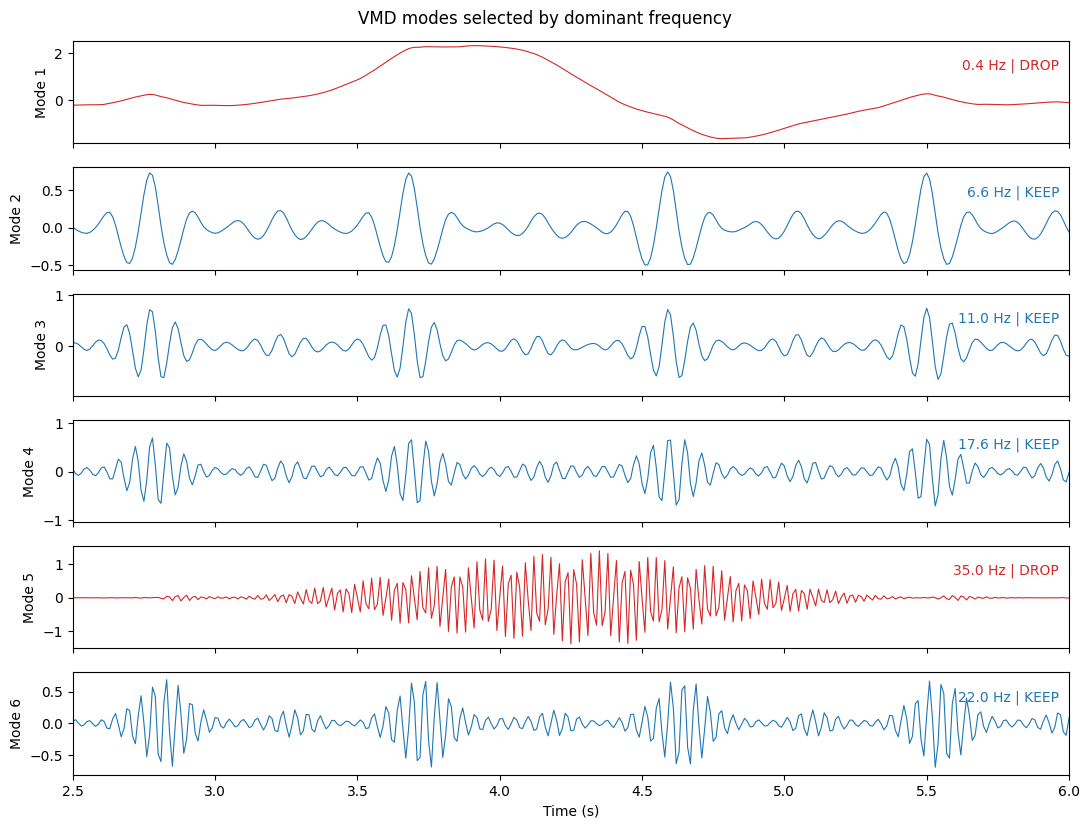

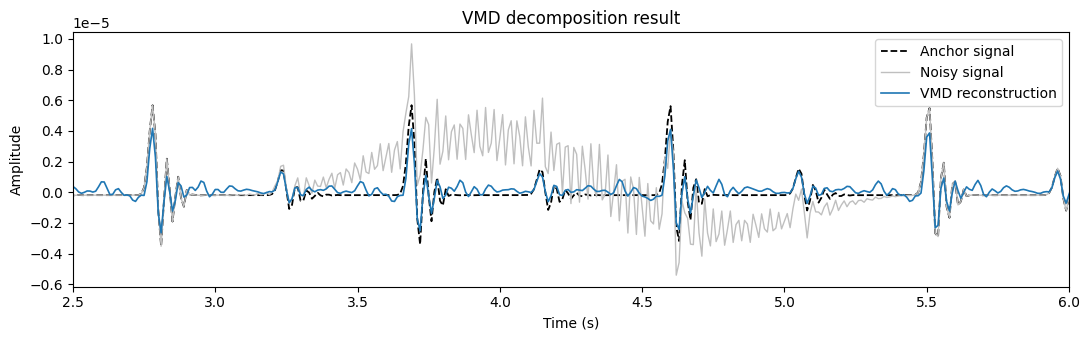

In [18]:
vmd_modes = vmd_decomposition(motion_noisy, K=6, alpha=2000)
vmd_peak_hz = np.array([dominant_frequency(mode) for mode in vmd_modes])
vmd_keep = (vmd_peak_hz >= 1.0) & (vmd_peak_hz <= 25.0)
vmd_reconstructed_standardized = vmd_modes[vmd_keep].sum(axis=0)
vmd_cleaned = (
    vmd_reconstructed_standardized * motion_noisy.std() + motion_noisy.mean()
)

fig, axes = plt.subplots(len(vmd_modes), 1, figsize=(11, 1.4 * len(vmd_modes)), sharex=True)
for i, (ax, mode, peak_hz, use) in enumerate(zip(axes, vmd_modes, vmd_peak_hz, vmd_keep)):
    ax.plot(t, mode, lw=0.8, color='tab:blue' if use else 'tab:red')
    ax.set_ylabel(f'Mode {i + 1}')
    ax.text(.99, .72, f'{peak_hz:.1f} Hz | ' + ('KEEP' if use else 'DROP'),
            transform=ax.transAxes, ha='right',
            color='tab:blue' if use else 'tab:red')
axes[-1].set_xlabel('Time (s)')
axes[-1].set_xlim(2.5, 6.0)
fig.suptitle('VMD modes selected by dominant frequency')
plt.tight_layout(); plt.show()

compare(motion_noisy, {'VMD reconstruction': vmd_cleaned},
        'VMD decomposition result', xlim=(2.5, 6.0))